# 02d – Round 3: final training run

Same data as round 2 (55 training areas = 21 from round 1 + 34 from round 2; validation and test unchanged),
with the corrections from the review of round 2 and one more model variant:

| Change | Why |
|---|---|
| Normalisation statistics computed in **float64** (with a check that mean(VV − VH) = mean(VV) − mean(VH)) | In round 2 the means were accumulated in float32 over 31 million values; the VV − VH mean was 6.92 instead of 7.80 |
| The control run gets **its own normalisation** from the 21 round-1 areas | In round 2 it used statistics of all 55 areas |
| **40 epochs** at most (as in round 1), early stopping unchanged | In round 2 three models reached the 30-epoch limit |
| New variant **SegFormer-B3** (28 transformer blocks instead of 16 in B2) | A larger pretrained encoder might help |
| Split check (area names per split), validation confusion matrix, pre-flight on a training batch, before/after-reload prediction check | Clearer evidence |

Round 2 (notebook 02b, `models/round2/`) is kept unchanged as history. Everything of this run is saved in `models/round3/`.

Rules as before: Sentinel-1 (VV, VH, VV − VH) is the only input; label 255 is excluded from loss and metrics;
normalisation comes from the training data only; the model is selected on validation mIoU and the test set only
reports results.

Before the long training, a **pre-flight check** builds every model and trains it on one training batch.
A model that fails there is skipped, so no GPU hours are lost on it.

# Preliminaries

In [1]:
import sys
import subprocess
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()

# keras-hub (for SegFormer) is installed WITHOUT its dependencies: a normal install
# pulls in another TensorFlow version and breaks the existing one.
# The keras-hub version must fit the installed Keras: 0.33.0 needs Keras >= 3.15,
# 0.24.0 works with Keras 3.8 - 3.14 (tested with TensorFlow 2.20 + Keras 3.11.2).
from importlib.metadata import version as package_version, PackageNotFoundError

keras_version = tuple(int(part) for part in package_version("keras").split(".")[:2])
KERAS_HUB = "0.33.0" if keras_version >= (3, 15) else "0.24.0"

try:
    installed = package_version("keras-hub")
except PackageNotFoundError:
    installed = None

if installed != KERAS_HUB:
    print(f"installing keras-hub {KERAS_HUB} (found: {installed}) for Keras {package_version('keras')}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--force-reinstall",
                    f"keras-hub=={KERAS_HUB}"], check=True)
    if "keras_hub" in sys.modules:
        raise RuntimeError("keras-hub was replaced - restart the kernel and run this cell again")

# small helpers keras-hub needs: downloads from Kaggle Models / Hugging Face (no TensorFlow dependency)
missing = []
for package in ["kagglehub", "huggingface_hub", "regex", "rich"]:
    try:
        package_version(package.replace("_", "-"))
    except PackageNotFoundError:
        missing.append(package)
if missing:
    print("installing", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

import keras_hub
print("keras-hub:", keras_hub.__version__)

installing keras-hub 0.24.0 (found: None) for Keras 3.11.2


installing ['kagglehub']


keras-hub: 0.24.0


A red pip message saying that keras-hub requires `tensorflow-text` is expected: keras-hub is installed without its
dependencies on purpose (`tensorflow-text` would replace the installed TensorFlow), and SegFormer does not use it.

In [2]:
import os
import json
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

import tensorflow as tf
import keras
from keras import layers

np.random.seed(14)
tf.random.set_seed(19)
keras.utils.set_random_seed(19)

GPUS = tf.config.list_physical_devices("GPU")
if GPUS:
    # float16 on the GPU: about twice as fast on a Tesla T4, the last layer stays float32
    keras.mixed_precision.set_global_policy("mixed_float16")

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| GPUs:", GPUS)

# record the exact environment of this training run (for the README)
from importlib.metadata import version as package_version
environment = {"python": sys.version.split()[0],
               "gpu": [d.name for d in GPUS],
               "mixed_precision": bool(GPUS)}
for package in ["tensorflow", "keras", "keras-hub", "numpy"]:
    try:
        environment[package] = package_version(package)
    except Exception:
        environment[package] = "not found"
Path("models/round3").mkdir(parents=True, exist_ok=True)
Path("models/round3/environment.json").write_text(json.dumps(environment, indent=2))
print(environment)

TensorFlow: 2.20.0 | Keras: 3.11.2 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
{'python': '3.11.13', 'gpu': ['/physical_device:GPU:0'], 'mixed_precision': True, 'tensorflow': '2.20.0', 'keras': '3.11.2', 'keras-hub': '0.24.0', 'numpy': '2.3.2'}


# Data

The patch sets are found by their `classes.json` (in `data/` or in the attached Kaggle inputs):
- `v2`: round-1 patches (train, validation, test), with the current class scheme (snow ignored)
- `v3_extra`: round-2 patches (train only)

All sets must use exactly the same classes and the same WorldCover mapping.

In [3]:
REQUIRED_VERSIONS = ["v2", "v3_extra"]


def find_patch_sets():
    roots = [Path("data")] + ([Path("/kaggle/input")] if ON_KAGGLE else [])
    found = {}
    for root in roots:
        for folder, _, files in os.walk(root, followlinks=True):
            if "classes.json" in files and any(f.endswith("_x.npy") for f in files):
                info = json.loads((Path(folder) / "classes.json").read_text())
                found.setdefault(info.get("plan_version"), []).append((Path(folder), info))

    for version, copies in found.items():
        if len(copies) > 1:
            raise RuntimeError(f"patch set {version} found {len(copies)} times, attach it only once: "
                               + ", ".join(str(folder) for folder, _ in copies))
    missing = [v for v in REQUIRED_VERSIONS if v not in found]
    if missing:
        raise RuntimeError(f"missing patch sets {missing} – attach the 01 and 01b notebook outputs")
    unexpected = [v for v in found if v not in REQUIRED_VERSIONS]
    if unexpected:
        raise RuntimeError(f"unexpected patch sets {unexpected} – remove these inputs")
    return {version: found[version][0] for version in REQUIRED_VERSIONS}


patch_sets = find_patch_sets()
for version, (folder, _) in patch_sets.items():
    print(f"{version:<10} {folder}")

infos = [info for _, info in patch_sets.values()]
for info in infos[1:]:
    assert info["classes"] == infos[0]["classes"], "patch sets use different classes"
    assert info["worldcover_to_class"] == infos[0]["worldcover_to_class"], "patch sets use different mappings"

CLASSES = infos[0]["classes"]
IGNORE = infos[0]["ignore"]
N_CLASSES = len(CLASSES)
COLORS = ["#006400", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4", "#0064c8", "#0096a0"]

v2         data/patches_v2
v3_extra   data/patches_v3_extra


In [4]:
data = {}
for split in ["train", "validation", "test"]:
    xs, ys, metas, sources, versions = [], [], [], [], []
    for version, (folder, _) in sorted(patch_sets.items()):
        if not (folder / f"{split}_x.npy").exists():
            continue
        xs.append(np.load(folder / f"{split}_x.npy"))
        ys.append(np.load(folder / f"{split}_y.npy"))
        rows = (folder / f"{split}_meta.csv").read_text().strip().split("\n")[1:]
        metas += [row.split(",") for row in rows]
        sources.append(f"{version}: {len(xs[-1])}")
        versions += [version] * len(xs[-1])
    data[split] = {"x": np.concatenate(xs), "y": np.concatenate(ys), "meta": metas, "version": np.array(versions)}
    print(f"{split:<11} {data[split]['x'].shape}  ({', '.join(sources)})")

    # validation and test must come from round 1 only, otherwise the rounds are not comparable
    if split != "train":
        assert len(sources) == 1 and sources[0].startswith("v2"), f"{split} must come only from v2"

train       (7538, 256, 256, 2)  (v2: 2920, v3_extra: 4618)
validation  (864, 256, 256, 2)  (v2: 864)
test        (864, 256, 256, 2)  (v2: 864)


## Split check

Every area must belong to exactly one split. The table also shows how many patches each area contributes.

In [5]:
areas_per_split = {}
for split in ["train", "validation", "test"]:
    names = [row[0] for row in data[split]["meta"]]
    areas_per_split[split] = sorted(set(names))
    counts = {name: names.count(name) for name in areas_per_split[split]}
    print(f"{split}: {len(counts)} areas, {len(names)} patches")
    print("   " + ", ".join(f"{name} ({n})" for name, n in counts.items()))

for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = set(areas_per_split[a]) & set(areas_per_split[b])
    assert not overlap, f"areas in both {a} and {b}: {overlap}"
assert len(areas_per_split["train"]) == 55, "expected 21 + 34 = 55 training areas"
print("\nno area is in two splits")

train: 55 areas, 7538 patches
   Abisko (144), Addis_Ababa (100), Alberta_prairie (144), Alice_Springs (144), Andalusia_farmland (144), Antofagasta (144), Astana_steppe (144), Auckland (128), Bogota (100), Brisbane (120), Buenos_Aires (144), Cairo (144), Camargue (144), Chicago (128), Danube_delta (144), Darwin_wetlands (144), Delhi (144), Dhaka (144), Dublin (144), Everglades_edge (144), Guadalajara (112), Iowa_farmland (144), Jakarta (144), Jyvaskyla_forest (144), Kano_rural (120), Kinshasa (100), Lagos (100), Lima (144), Ludhiana_rural (144), Lyon (144), Madrid (144), Manaus_edge (144), Marrakech_edge (144), Mekong_delta (144), Melbourne (144), Mexico_City (100), Nairobi (144), Nile_delta (144), Okavango (144), Ouarzazate (144), Pantanal (94), Phoenix_edge (144), Po_valley (144), Poyang_lake (144), Pune (144), Riyadh_edge (144), Rosario_rural (144), Sacramento_rural (144), Santarem_edge (144), Sao_Paulo (144), Sundarbans (144), Tabernas_desert (144), Tehran (144), Wagga_rural (144),

## Class distribution and class weights

In [6]:
def class_frequency(labels):
    counts = np.bincount(labels[labels != IGNORE].ravel(), minlength=N_CLASSES)
    return counts / counts.sum()


def median_frequency_weights(frequency):
    present = frequency > 0
    weights = np.zeros(N_CLASSES, dtype=np.float32)
    weights[present] = np.median(frequency[present]) / frequency[present]
    return np.clip(weights, 0, 10)


V2_ONLY = np.flatnonzero(data["train"]["version"] == "v2")
frequency = class_frequency(data["train"]["y"])
class_weights = median_frequency_weights(frequency)
class_weights_v2 = median_frequency_weights(class_frequency(data["train"]["y"][V2_ONLY]))

round1 = [24.40, 15.24, 15.91, 36.08, 2.45, 5.42, 0.49]    # training share in round 1 (notebook 01 output)
print(f"{'class':<26}{'round 1 %':>10}{'round 2 %':>10}{'weight':>8}")
for name, r1, f, w in zip(CLASSES, round1, frequency, class_weights):
    print(f"{name:<26}{r1:10.2f}{100 * f:10.2f}{w:8.2f}")

class                      round 1 % round 2 %  weight
Trees (incl. mangroves)        24.40     18.32    0.75
Grassland / shrubland          15.24     15.24    0.90
Cropland                       15.91     13.67    1.00
Built-up                       36.08     31.95    0.43
Bare / sparse vegetation        2.45      6.67    2.05
Permanent water                 5.42      7.19    1.90
Herbaceous wetland              0.49      6.96    1.96


## Normalisation (training data only)

In [7]:
ADD_RATIO = True


def channel_statistics(indices):
    # every 4th pixel of the given training patches; float64 accumulation (float32 loses precision over millions of values)
    sample = data["train"]["x"][indices, ::4, ::4, :].astype(np.float32).reshape(-1, 2)
    low = np.percentile(sample, 0.5, axis=0)
    high = np.percentile(sample, 99.5, axis=0)
    sample = np.clip(sample, low, high)
    if ADD_RATIO:
        sample = np.concatenate([sample, sample[:, :1] - sample[:, 1:2]], axis=1)
    mean = sample.mean(axis=0, dtype=np.float64)
    std = sample.std(axis=0, dtype=np.float64)

    assert np.isfinite(mean).all() and np.isfinite(std).all() and (std > 0).all()
    if ADD_RATIO:
        np.testing.assert_allclose(mean[2], mean[0] - mean[1], atol=1e-4)
    return {
        "channels": ["VV", "VH", "VV-VH"] if ADD_RATIO else ["VV", "VH"],
        "add_ratio": ADD_RATIO,
        "clip_low": low.astype(float).tolist(),
        "clip_high": high.astype(float).tolist(),
        "mean": mean.tolist(),
        "std": std.tolist(),
        "patches": int(len(indices)),
    }


ALL_TRAIN = np.arange(len(data["train"]["x"]))
stats_all = channel_statistics(ALL_TRAIN)     # used by all candidate models and the prototype
stats_v2 = channel_statistics(V2_ONLY)        # only for the control run (round-1 areas)

model_folder = Path("models/round3")
model_folder.mkdir(parents=True, exist_ok=True)
(model_folder / "normalisation.json").write_text(json.dumps(stats_all, indent=2))

for label, st in [("all 55 areas", stats_all), ("round-1 areas", stats_v2)]:
    print(f"{label:<14} mean {np.round(st['mean'], 4)}  std {np.round(st['std'], 4)}  "
          f"clip {np.round(st['clip_low'], 2)} .. {np.round(st['clip_high'], 2)}")
print("round 2 (float32, for comparison): mean [-9.2795 -17.079 6.9206]")

all 55 areas   mean [ -9.774 -17.149   7.375]  std [5.1745 5.3723 3.0961]  clip [-24.36 -30.58] .. [ 6.16 -2.8 ]
round-1 areas  mean [ -9.3685 -16.6039   7.2353]  std [4.9062 5.1149 3.0257]  clip [-23.09 -30.55] .. [ 6.45 -2.46]
round 2 (float32, for comparison): mean [-9.2795 -17.079 6.9206]


## Input pipeline

The training patches are now about 2 GB. `tf.data.Dataset.from_tensor_slices` cannot hold arrays
larger than 2 GB, so the dataset only holds patch **numbers**, and each patch is read from the NumPy array when needed.

In [8]:
N_CHANNELS = 3 if ADD_RATIO else 2
BATCH_SIZE = 16


def normalise(x, stats):
    x = tf.clip_by_value(x, np.float32(stats["clip_low"]), np.float32(stats["clip_high"]))
    if stats["add_ratio"]:
        x = tf.concat([x, x[..., :1] - x[..., 1:2]], axis=-1)
    return (x - np.float32(stats["mean"])) / np.float32(stats["std"])


def augment(x, y):
    xy = tf.concat([x, tf.cast(y[..., tf.newaxis], tf.float32)], axis=-1)
    xy = tf.image.random_flip_left_right(xy)
    xy = tf.image.random_flip_up_down(xy)
    xy = tf.image.rot90(xy, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    return xy[..., :-1], tf.cast(xy[..., -1], tf.uint8)


def make_dataset(split, stats, training=False, indices=None):
    x_all, y_all = data[split]["x"], data[split]["y"]
    if indices is None:
        indices = np.arange(len(x_all))
    indices = indices.astype(np.int64)

    def load(i):
        return x_all[i].astype(np.float32), y_all[i]

    def load_tf(i):
        x, y = tf.numpy_function(load, [i], [tf.float32, tf.uint8])
        x.set_shape((256, 256, 2))
        y.set_shape((256, 256))
        return normalise(x, stats), y

    ds = tf.data.Dataset.from_tensor_slices(indices)
    if training:
        ds = ds.shuffle(len(indices), seed=14, reshuffle_each_iteration=True)
    ds = ds.map(load_tf, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


datasets = {
    "all": {"train": make_dataset("train", stats_all, training=True),
            "validation": make_dataset("validation", stats_all),
            "test": make_dataset("test", stats_all)},
    # control run: round-1 training patches AND round-1 normalisation, also for its evaluation
    "v2": {"train": make_dataset("train", stats_v2, training=True, indices=V2_ONLY),
           "validation": make_dataset("validation", stats_v2),
           "test": make_dataset("test", stats_v2)},
}
valid_ds = datasets["all"]["validation"]

# Loss and metrics (label 255 ignored)

In [9]:
def make_masked_loss(weights):
    weights_tensor = tf.constant(weights)

    def masked_loss(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        y_pred = tf.cast(y_pred, tf.float32)
        valid = tf.not_equal(y_true, IGNORE)
        y_safe = tf.where(valid, y_true, 0)

        pixel_loss = keras.losses.sparse_categorical_crossentropy(y_safe, y_pred)
        pixel_weight = tf.gather(weights_tensor, y_safe) * tf.cast(valid, tf.float32)
        return tf.reduce_sum(pixel_loss * pixel_weight) / tf.maximum(tf.reduce_sum(pixel_weight), 1.0)

    return masked_loss


def masked_accuracy(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)
    valid = tf.not_equal(y_true, IGNORE)
    correct = tf.equal(tf.cast(tf.argmax(y_pred, axis=-1), tf.int32), y_true)
    return tf.reduce_sum(tf.cast(correct & valid, tf.float32)) / tf.maximum(
        tf.reduce_sum(tf.cast(valid, tf.float32)), 1.0)

In [10]:
def predict_split(model, dataset):
    return np.concatenate([np.argmax(model.predict_on_batch(xb), axis=-1) for xb, _ in dataset]).astype(np.uint8)


def confusion(y_true, y_pred):
    valid = y_true != IGNORE
    index = N_CLASSES * y_true[valid].astype(np.int64) + y_pred[valid]
    return np.bincount(index, minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)


def scores(cm):
    # F1 = 2 TP / (actual + predicted): a class that is present but never predicted gets F1 = 0, not NaN
    cm = np.asarray(cm, dtype=np.float64)
    tp = np.diag(cm)
    actual = cm.sum(axis=1)
    predicted = cm.sum(axis=0)
    union = actual + predicted - tp
    iou = np.divide(tp, union, out=np.full(tp.shape, np.nan), where=union > 0)
    f1 = np.divide(2 * tp, actual + predicted, out=np.full(tp.shape, np.nan), where=(actual + predicted) > 0)
    return {
        "oa": tp.sum() / cm.sum() if cm.sum() else np.nan,
        "miou": np.nanmean(iou) if np.any(union > 0) else np.nan,
        "iou": iou,
        "f1": f1,
    }


class ValidationIoU(keras.callbacks.Callback):
    def __init__(self, dataset, y_true):
        super().__init__()
        self.dataset = dataset
        self.y_true = y_true

    def on_epoch_end(self, epoch, logs=None):
        y_pred = predict_split(self.model, self.dataset)
        logs["val_miou"] = scores(confusion(self.y_true, y_pred))["miou"]
        print(f" - val_miou: {logs['val_miou']:.4f}")

# Models

In [11]:
def conv_block(x, filters):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    return x


def classifier(x):
    # softmax in float32, also when the rest of the model runs in float16
    x = layers.Conv2D(N_CLASSES, 1)(x)
    return layers.Activation("softmax", dtype="float32")(x)

### 1. U-Net from scratch (same as round 1)

In [12]:
def build_unet(base_filters=32, dropout=0.3):
    inputs = keras.Input(shape=(256, 256, N_CHANNELS))
    skips = []
    x = inputs
    for level in range(4):
        x = conv_block(x, base_filters * 2 ** level)
        skips.append(x)
        x = layers.MaxPooling2D()(x)

    x = conv_block(x, base_filters * 16)
    x = layers.Dropout(dropout)(x)

    for level in reversed(range(4)):
        x = layers.Conv2DTranspose(base_filters * 2 ** level, 2, strides=2, padding="same")(x)
        x = layers.Concatenate()([x, skips[level]])
        x = conv_block(x, base_filters * 2 ** level)
    return keras.Model(inputs, classifier(x), name="unet_scratch")

### 2. U-Net with ResNet50 encoder (ImageNet), same as round 1

In [13]:
def build_resnet_unet(dropout=0.3):
    encoder = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(256, 256, 3))
    skip_names = ["conv1_relu", "conv2_block3_out", "conv3_block4_out", "conv4_block6_out"]
    skips = [encoder.get_layer(name).output for name in skip_names]

    x = encoder.get_layer("conv5_block3_out").output
    x = layers.Dropout(dropout)(x)
    for skip, filters in zip(reversed(skips), [256, 128, 64, 32]):
        x = layers.UpSampling2D()(x)
        x = layers.Concatenate()([x, skip])
        x = conv_block(x, filters)

    x = layers.UpSampling2D()(x)
    x = conv_block(x, 16)
    return keras.Model(encoder.input, classifier(x), name="unet_resnet50")

### 3. DeepLabV3+ with ResNet50 encoder (ImageNet)

The encoder output (16 × 16) goes through **ASPP**: parallel 3 × 3 convolutions with different dilation rates
plus global pooling, so every pixel sees context at several scales. The decoder adds the fine 64 × 64 features
from the encoder and upsamples to 256 × 256. The dilation rates are smaller than in the paper (3, 6, 9 instead of
6, 12, 18) because our feature map is only 16 × 16.

In [14]:
def conv_bn_relu(x, filters, kernel=1, dilation=1):
    x = layers.Conv2D(filters, kernel, padding="same", dilation_rate=dilation, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)


def build_deeplabv3plus(dropout=0.3):
    encoder = keras.applications.ResNet50(include_top=False, weights="imagenet", input_shape=(256, 256, 3))
    high = encoder.get_layer("conv4_block6_out").output      # 16 x 16
    low = encoder.get_layer("conv2_block3_out").output       # 64 x 64

    pooled = layers.GlobalAveragePooling2D(keepdims=True)(high)
    pooled = conv_bn_relu(pooled, 256)
    pooled = layers.UpSampling2D(size=(16, 16), interpolation="bilinear")(pooled)

    branches = [pooled, conv_bn_relu(high, 256)]
    branches += [conv_bn_relu(high, 256, kernel=3, dilation=rate) for rate in (3, 6, 9)]
    x = layers.Concatenate()(branches)
    x = conv_bn_relu(x, 256)
    x = layers.Dropout(dropout)(x)

    x = layers.UpSampling2D(4, interpolation="bilinear")(x)  # 64 x 64
    x = layers.Concatenate()([x, conv_bn_relu(low, 48)])
    x = conv_bn_relu(x, 256, kernel=3)
    x = conv_bn_relu(x, 256, kernel=3)
    x = layers.UpSampling2D(4, interpolation="bilinear")(x)  # 256 x 256
    return keras.Model(encoder.input, classifier(x), name="deeplabv3plus_resnet50")

### 4. SegFormer-B2 and SegFormer-B3 (Mix Transformer encoder, pretrained on ADE20K)

B2 has 16 transformer blocks, B3 has 28 (same width). Both are built the same way.

The encoder uses self-attention, so it can relate pixels that are far apart. It has no fixed position
embeddings, so the weights trained on 512 × 512 images can be reused for our 256 × 256 patches:
the encoder is rebuilt for 256 × 256 with the same settings and the pretrained weights are copied in.
The SegFormer decoder outputs 1/4 resolution (64 × 64); it is upsampled to 256 × 256.

In [15]:
def pretrained_mit(size):
    # first choice: the MiT encoder preset (Kaggle Models)
    # backup: the same encoder taken out of the SegFormer ADE20K preset on Hugging Face
    loaders = {
        f"kaggle mit_{size}_ade20k_512": lambda: keras_hub.models.MiTBackbone.from_preset(f"mit_{size}_ade20k_512"),
        f"huggingface segformer_{size}_ade20k_512": lambda: keras_hub.models.SegFormerBackbone.from_preset(
            f"hf://keras/segformer_{size}_ade20k_512").image_encoder,
    }
    errors = []
    for source, load in loaders.items():
        try:
            encoder = load()
            print(f"pretrained MiT-{size.upper()} weights from", source)
            return encoder
        except Exception as error:
            errors.append(f"{source}: {type(error).__name__}: {str(error)[:200]}")
    raise RuntimeError(f"no pretrained MiT-{size.upper()} weights could be downloaded -> " + " | ".join(errors))


def build_segformer(size="b2", dropout=0.1):
    pretrained = pretrained_mit(size)
    config = pretrained.get_config()
    config["image_shape"] = (256, 256, 3)
    encoder = keras_hub.models.MiTBackbone.from_config(config)
    encoder.set_weights(pretrained.get_weights())

    backbone = keras_hub.models.SegFormerBackbone(image_encoder=encoder, projection_filters=256)
    inputs = keras.Input(shape=(256, 256, N_CHANNELS))
    x = backbone(inputs)                                     # 64 x 64 x 256
    x = layers.Dropout(dropout)(x)
    x = layers.Conv2D(N_CLASSES, 1)(x)
    x = layers.UpSampling2D(4, interpolation="bilinear")(x)
    outputs = layers.Activation("softmax", dtype="float32")(x)
    return keras.Model(inputs, outputs, name=f"segformer_{size}")

# Training

Each variant is trained with the same data, loss, augmentation and callbacks.
If one variant fails (for example a download problem), the error is printed and the next one still runs.

In [16]:
EPOCHS = 40
TIME_BUDGET_HOURS = 10     # no new experiment is started after this (Kaggle stops a run after 12 h)

experiments = {
    "segformer_b2":           {"build": lambda: build_segformer("b2"),
                               "optimizer": lambda: keras.optimizers.AdamW(6e-5, weight_decay=0.01)},
    "segformer_b3":           {"build": lambda: build_segformer("b3"),
                               "optimizer": lambda: keras.optimizers.AdamW(6e-5, weight_decay=0.01)},
    "unet_resnet50":          {"build": build_resnet_unet,   "optimizer": lambda: keras.optimizers.Adam(1e-4)},
    "deeplabv3plus_resnet50": {"build": build_deeplabv3plus, "optimizer": lambda: keras.optimizers.Adam(1e-4)},
    "unet_scratch":           {"build": build_unet,          "optimizer": lambda: keras.optimizers.Adam(1e-3)},
    # control run: same model and settings as "unet_resnet50", but only the round-1 training patches,
    # with class weights AND normalisation computed from those patches
    "unet_resnet50_v2_only":  {"build": build_resnet_unet,   "optimizer": lambda: keras.optimizers.Adam(1e-4),
                               "data": "v2", "class_weights": class_weights_v2},
}


def run_experiment(name):
    settings = experiments[name]
    keras.backend.clear_session()
    keras.utils.set_random_seed(19)

    model = settings["build"]()
    loss = make_masked_loss(settings.get("class_weights", class_weights))
    model.compile(optimizer=settings["optimizer"](), loss=loss, metrics=[masked_accuracy])
    print(f"\n{name}: {model.count_params():,} parameters")

    folder = model_folder / name
    folder.mkdir(parents=True, exist_ok=True)
    ds = datasets[settings.get("data", "all")]
    stats = stats_v2 if settings.get("data") == "v2" else stats_all
    (folder / "normalisation.json").write_text(json.dumps(stats, indent=2))   # the statistics this model was trained with

    callbacks = [
        ValidationIoU(ds["validation"], data["validation"]["y"]),
        keras.callbacks.ModelCheckpoint(folder / "best.keras", monitor="val_miou", mode="max", save_best_only=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_miou", mode="max", factor=0.5, patience=3),
        keras.callbacks.EarlyStopping(monitor="val_miou", mode="max", patience=8),
        keras.callbacks.CSVLogger(folder / "history.csv"),
    ]

    start = time.time()
    history = model.fit(ds["train"], validation_data=ds["validation"], epochs=EPOCHS, callbacks=callbacks)
    history = {key: [float(v) for v in values] for key, values in history.history.items()}
    history["minutes"] = (time.time() - start) / 60
    history["parameters"] = model.count_params()
    (folder / "history.json").write_text(json.dumps(history, indent=2))
    print(f"{name}: {history['minutes']:.0f} minutes, best val mIoU {max(history['val_miou']):.4f}")

## Pre-flight check (a few minutes)

Every model is built (this also downloads the pretrained weights), trained on one full training batch
(same batch size as in training, so a GPU memory problem also shows up here), saved, reloaded and checked. A model that fails here is removed from the run, so the long training
does not stop hours later because of it.

In [17]:
check_x, check_y = next(iter(datasets["all"]["train"]))   # one full training batch of BATCH_SIZE patches
n_check = int(check_x.shape[0])
preflight_failed = {}

for name, settings in list(experiments.items()):
    start = time.time()
    model = None
    try:
        keras.backend.clear_session()
        model = settings["build"]()
        model.compile(optimizer=settings["optimizer"](), loss=make_masked_loss(class_weights),
                      metrics=[masked_accuracy])
        loss_value = float(np.ravel(model.train_on_batch(check_x, check_y))[0])
        probabilities = np.asarray(model.predict_on_batch(check_x))
        assert probabilities.shape == (n_check, 256, 256, N_CLASSES), f"wrong output shape {probabilities.shape}"
        assert np.isfinite(probabilities).all() and np.isfinite(loss_value), "NaN in output or loss"

        path = model_folder / "preflight_check.keras"
        model.save(path)
        reloaded = np.asarray(keras.models.load_model(path, compile=False).predict_on_batch(check_x))
        path.unlink()
        assert np.allclose(probabilities, reloaded, atol=1e-2), "reloaded model predicts differently"
        print(f"OK    {name:<24}{model.count_params() / 1e6:6.1f}M parameters  loss {loss_value:.3f}  "
              f"({time.time() - start:.0f} s)")
    except Exception as error:
        preflight_failed[name] = f"{type(error).__name__}: {error}"
        print(f"FAIL  {name:<24}{preflight_failed[name][:400]}")
        if "ResourceExhausted" in type(error).__name__ or "OOM" in str(error):
            print("      -> not enough GPU memory: set BATCH_SIZE = 8 in the input pipeline cell and run again")
    finally:
        model = None
        keras.backend.clear_session()

for name in preflight_failed:
    experiments.pop(name)
print("\nmodels for the training run:", list(experiments))
if preflight_failed:
    print("!!! skipped after the pre-flight check:", list(preflight_failed))

100%|██████████| 978/978 [00:00<00:00, 3.49MB/s]


100%|██████████| 93.0M/93.0M [00:03<00:00, 29.4MB/s]


pretrained MiT-B2 weights from kaggle mit_b2_ade20k_512


OK    segformer_b2              24.7M parameters  loss 2.365  (162 s)


100%|██████████| 979/979 [00:00<00:00, 3.02MB/s]


100%|██████████| 169M/169M [00:06<00:00, 25.7MB/s] 


pretrained MiT-B3 weights from kaggle mit_b3_ade20k_512
OK    segformer_b3              44.6M parameters  loss 2.301  (241 s)
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
OK    unet_resnet50             32.6M parameters  loss 2.301  (57 s)
OK    deeplabv3plus_resnet50    17.8M parameters  loss 2.477  (42 s)
OK    unet_scratch               7.8M parameters  loss 2.265  (24 s)
OK    unet_resnet50_v2_only     32.6M parameters  loss 2.109  (43 s)

models for the training run: ['segformer_b2', 'segformer_b3', 'unet_resnet50', 'deeplabv3plus_resnet50', 'unet_scratch', 'unet_resnet50_v2_only']


## Training run

In [18]:
finished = []
run_start = time.time()
for name in experiments:
    if (time.time() - run_start) / 3600 > TIME_BUDGET_HOURS:
        print(f"\n!!! time budget reached, {name} is skipped")
        continue
    try:
        run_experiment(name)
        finished.append(name)
    except Exception as error:
        print(f"\n!!! {name} failed: {type(error).__name__}: {error}")

print("\nFinished:", finished)
if preflight_failed:
    print("Skipped in the pre-flight check:", list(preflight_failed))

pretrained MiT-B2 weights from kaggle mit_b2_ade20k_512

segformer_b2: 24,724,423 parameters
Epoch 1/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 1.1336 - masked_accuracy: 0.5947

472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - loss: 1.1331 - masked_accuracy: 0.5948 - val_miou: 0.3218
472/472 ━━━━━━━━━━━━━━━━━━━━ 267s 309ms/step - loss: 0.8949 - masked_accuracy: 0.6759 - val_loss: 1.1495 - val_masked_accuracy: 0.5830 - val_miou: 0.3218 - learning_rate: 6.0000e-05
Epoch 2/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 0.6683 - masked_accuracy: 0.7481 - val_miou: 0.3068
472/472 ━━━━━━━━━━━━━━━━━━━━ 46s 97ms/step - loss: 0.6456 - masked_accuracy: 0.7532 - val_loss: 1.2572 - val_masked_accuracy: 0.5792 - val_miou: 0.3068 - learning_rate: 6.0000e-05
Epoch 3/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - loss: 0.5975 - masked_accuracy: 0.7683 - val_miou: 0.3460
472/472 ━━━━━━━━━━━━━━━━━━━━ 50s 106ms/step - loss: 0.5814 - masked_accuracy: 0.7736 - val_loss: 1.0969 - val_masked_accuracy: 0.5997 - val_miou: 0.3460 - learning_rate: 6.0000e-05
Epoch 4/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - loss: 0.5429 - masked_accuracy: 0.7843 - val_miou: 0.3391
472/472 ━━━━━━━

472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - loss: 1.1225 - masked_accuracy: 0.6000 - val_miou: 0.0256
472/472 ━━━━━━━━━━━━━━━━━━━━ 135s 224ms/step - loss: 0.9083 - masked_accuracy: 0.6706 - val_loss: 25.0328 - val_masked_accuracy: 0.0853 - val_miou: 0.0256 - learning_rate: 1.0000e-04
Epoch 2/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - loss: 0.7233 - masked_accuracy: 0.7284 - val_miou: 0.2741
472/472 ━━━━━━━━━━━━━━━━━━━━ 68s 144ms/step - loss: 0.7095 - masked_accuracy: 0.7313 - val_loss: 1.2533 - val_masked_accuracy: 0.4829 - val_miou: 0.2741 - learning_rate: 1.0000e-04
Epoch 3/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - loss: 0.6684 - masked_accuracy: 0.7440 - val_miou: 0.3041
472/472 ━━━━━━━━━━━━━━━━━━━━ 67s 142ms/step - loss: 0.6504 - masked_accuracy: 0.7477 - val_loss: 1.1505 - val_masked_accuracy: 0.5632 - val_miou: 0.3041 - learning_rate: 1.0000e-04
Epoch 4/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - loss: 0.6660 - masked_accuracy: 0.7458 - val_miou: 0.3239
472/472 ━━

472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - loss: 1.4509 - masked_accuracy: 0.5004 - val_miou: 0.2274
472/472 ━━━━━━━━━━━━━━━━━━━━ 64s 113ms/step - loss: 1.3705 - masked_accuracy: 0.5241 - val_loss: 1.3841 - val_masked_accuracy: 0.4737 - val_miou: 0.2274 - learning_rate: 0.0010
Epoch 2/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 1.2301 - masked_accuracy: 0.5664 - val_miou: 0.2554
472/472 ━━━━━━━━━━━━━━━━━━━━ 43s 91ms/step - loss: 1.2122 - masked_accuracy: 0.5686 - val_loss: 1.2949 - val_masked_accuracy: 0.5280 - val_miou: 0.2554 - learning_rate: 0.0010
Epoch 3/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 1.1324 - masked_accuracy: 0.5886 - val_miou: 0.2742
472/472 ━━━━━━━━━━━━━━━━━━━━ 43s 91ms/step - loss: 1.1165 - masked_accuracy: 0.5951 - val_loss: 1.1851 - val_masked_accuracy: 0.5276 - val_miou: 0.2742 - learning_rate: 0.0010
Epoch 4/40
471/472 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 1.0863 - masked_accuracy: 0.6053 - val_miou: 0.3082
472/472 ━━━━━━━━━━━━━━━━━━━━ 4

# Training performance

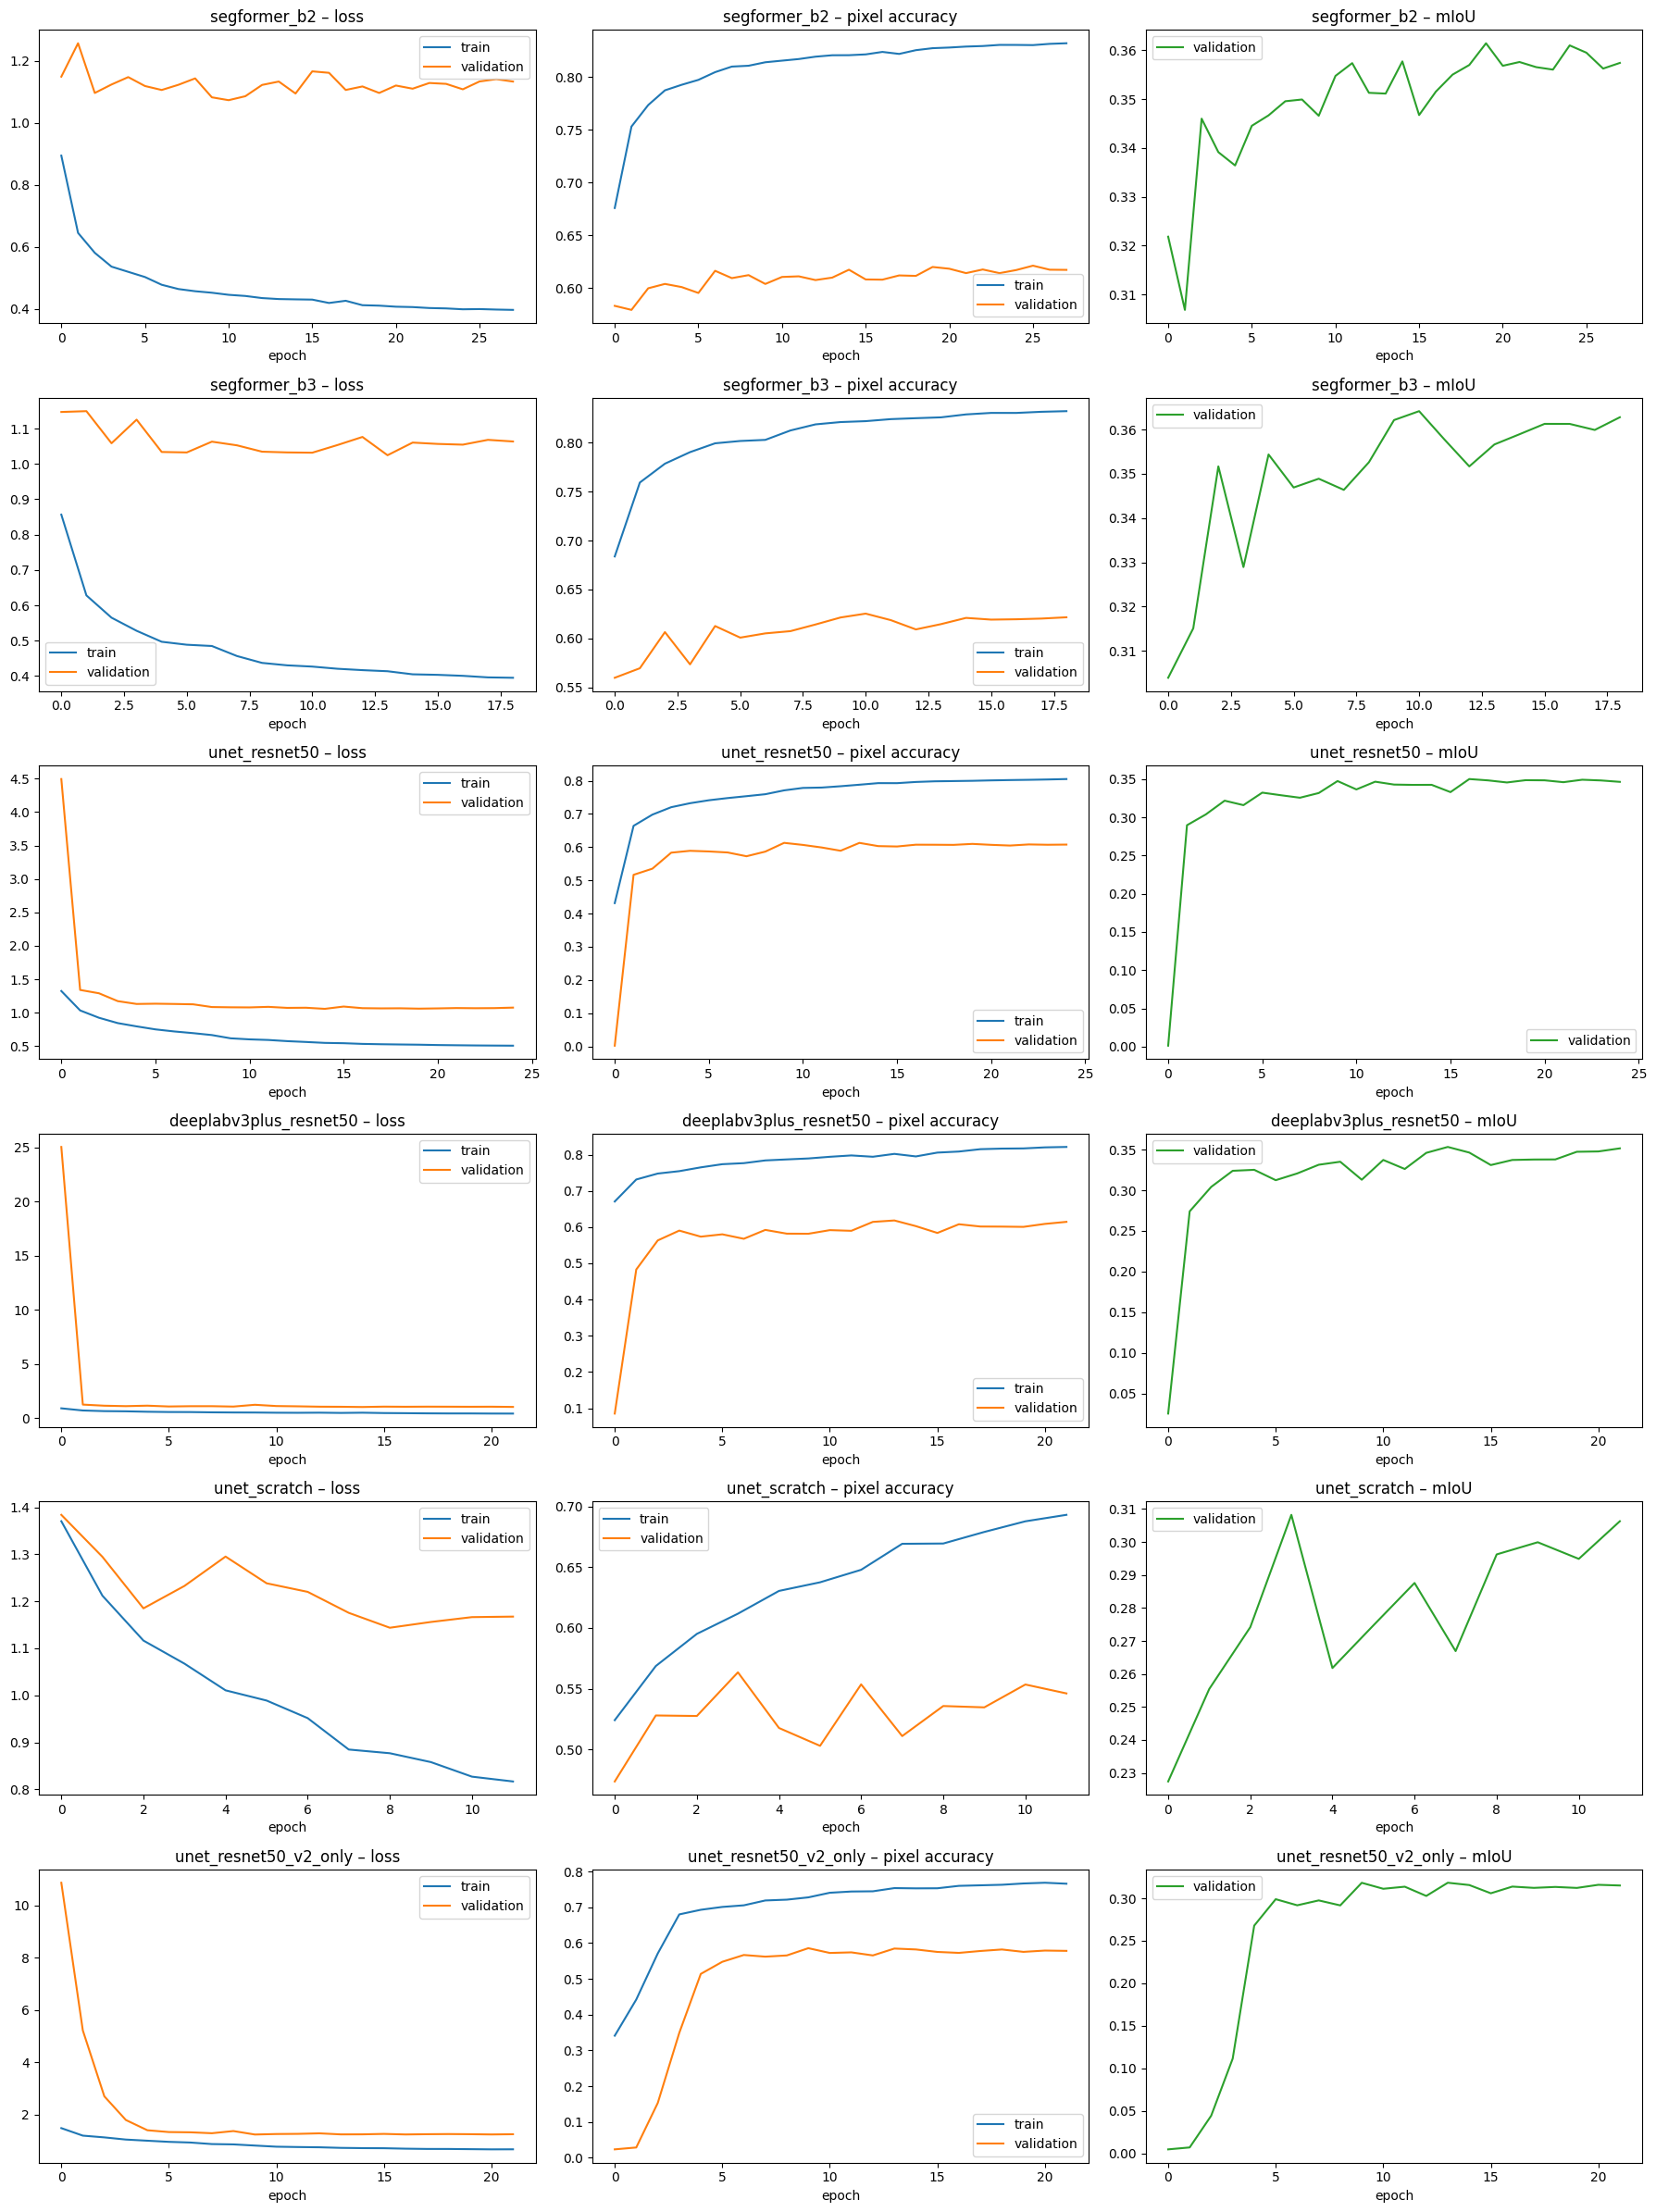

In [19]:
fig, axes = plt.subplots(len(finished), 3, figsize=(18, 4 * len(finished)), squeeze=False)
for row, name in enumerate(finished):
    history = json.loads((model_folder / name / "history.json").read_text())
    axes[row, 0].plot(history["loss"], label="train")
    axes[row, 0].plot(history["val_loss"], label="validation")
    axes[row, 0].set_title(f"{name} – loss")
    axes[row, 1].plot(history["masked_accuracy"], label="train")
    axes[row, 1].plot(history["val_masked_accuracy"], label="validation")
    axes[row, 1].set_title(f"{name} – pixel accuracy")
    axes[row, 2].plot(history["val_miou"], color="tab:green", label="validation")
    axes[row, 2].set_title(f"{name} – mIoU")
    for ax in axes[row]:
        ax.set_xlabel("epoch")
        ax.legend()
plt.tight_layout()
plt.show()

# Comparison

The model for the prototype is **selected on validation mIoU**. Test results are shown for all variants
so they can be compared in the report, but they are not used for the choice.
Round-1 numbers (notebook 02) are added as reference.

In [20]:
def load_trained(name):
    return keras.models.load_model(model_folder / name / "best.keras", compile=False)


results = {}
for name in finished:
    model = load_trained(name)
    history = json.loads((model_folder / name / "history.json").read_text())

    ds = datasets[experiments[name].get("data", "all")]
    start = time.time()
    valid_pred = predict_split(model, ds["validation"])
    seconds_per_patch = (time.time() - start) / len(valid_pred)

    results[name] = {
        "valid": scores(confusion(data["validation"]["y"], valid_pred)),
        "test_pred": predict_split(model, ds["test"]),
        "valid_pred": valid_pred,
        "parameters": history["parameters"],
        "minutes": history["minutes"],
        "epochs": len(history["loss"]),
        "ms_per_patch": 1000 * seconds_per_patch,
    }
    results[name]["test"] = scores(confusion(data["test"]["y"], results[name]["test_pred"]))

# the control run only answers "does more data help?", it is not a candidate for the prototype
candidates = [name for name in results if not name.endswith("_v2_only")]
best_name = max(candidates, key=lambda name: results[name]["valid"]["miou"])

print(f"{'model':<24}{'params':>12}{'epochs':>8}{'min':>6}{'ms/patch':>10}{'val OA':>8}{'val mIoU':>10}{'test OA':>9}{'test mIoU':>11}")
print(f"{'round 1: unet_scratch':<24}{'7.8M':>12}{17:>8}{'':>6}{'':>10}{0.576:8.3f}{0.317:10.3f}{'-':>9}{'-':>11}")
print(f"{'round 1: unet_resnet50':<24}{'32.6M':>12}{28:>8}{'':>6}{'':>10}{0.583:8.3f}{0.324:10.3f}{0.642:9.3f}{0.374:11.3f}")
print(f"{'round 2: segformer_b2':<24}{'24.7M':>12}{25:>8}{'':>6}{'':>10}{0.620:8.3f}{0.361:10.3f}{0.691:9.3f}{0.426:11.3f}")
for name, r in results.items():
    mark = "  <- selected" if name == best_name else ("  (control: round-1 data)" if name.endswith("_v2_only") else "")
    print(f"{name:<24}{r['parameters'] / 1e6:11.1f}M{r['epochs']:8d}{r['minutes']:6.0f}{r['ms_per_patch']:10.1f}"
          f"{r['valid']['oa']:8.3f}{r['valid']['miou']:10.3f}{r['test']['oa']:9.3f}{r['test']['miou']:11.3f}{mark}")

model                         params  epochs   min  ms/patch  val OA  val mIoU  test OA  test mIoU
round 1: unet_scratch           7.8M      17                   0.576     0.317        -          -
round 1: unet_resnet50         32.6M      28                   0.583     0.324    0.642      0.374
round 2: segformer_b2          24.7M      25                   0.620     0.361    0.691      0.426
segformer_b2                   24.7M      28    26      15.3   0.620     0.361    0.682      0.422
segformer_b3                   44.6M      19    28      20.8   0.625     0.364    0.692      0.428  <- selected
unet_resnet50                  32.6M      25    21       5.5   0.607     0.350    0.658      0.377
deeplabv3plus_resnet50         17.8M      22    25       6.4   0.618     0.353    0.664      0.394
unet_scratch                    7.8M      12     9       3.3   0.563     0.308    0.577      0.301
unet_resnet50_v2_only          32.6M      22     9       5.4   0.585     0.318    0.637      0.3

In [21]:
print("Validation IoU per class")
print(f"{'class':<26}" + "".join(f"{name[:14]:>16}" for name in results))
for i, class_name in enumerate(CLASSES):
    print(f"{class_name:<26}" + "".join(f"{results[name]['valid']['iou'][i]:16.3f}" for name in results))

print("\nTest IoU per class")
print(f"{'class':<26}" + "".join(f"{name[:14]:>16}" for name in results))
for i, class_name in enumerate(CLASSES):
    print(f"{class_name:<26}" + "".join(f"{results[name]['test']['iou'][i]:16.3f}" for name in results))

Validation IoU per class
class                         segformer_b2    segformer_b3   unet_resnet50  deeplabv3plus_    unet_scratch  unet_resnet50_
Trees (incl. mangroves)              0.500           0.508           0.464           0.484           0.410           0.440
Grassland / shrubland                0.413           0.406           0.411           0.421           0.379           0.400
Cropland                             0.299           0.336           0.299           0.283           0.189           0.235
Built-up                             0.547           0.557           0.541           0.559           0.569           0.548
Bare / sparse vegetation             0.128           0.117           0.111           0.096           0.088           0.090
Permanent water                      0.640           0.624           0.620           0.620           0.522           0.512
Herbaceous wetland                   0.002           0.002           0.004           0.009           0.000        

In [22]:
if "unet_resnet50" in results and "unet_resnet50_v2_only" in results:
    full, control = results["unet_resnet50"], results["unet_resnet50_v2_only"]
    print("Round-1 areas only vs. all 55 areas (same model and optimiser settings; each run with class weights and")
    print("normalisation from its own training patches; the larger set also gives more optimiser steps per epoch):")
    print(f"  validation mIoU: {control['valid']['miou']:.3f} -> {full['valid']['miou']:.3f} "
          f"({full['valid']['miou'] - control['valid']['miou']:+.3f})")
    for k, name in enumerate(CLASSES):
        print(f"  {name:<26} IoU {control['valid']['iou'][k]:.3f} -> {full['valid']['iou'][k]:.3f}")

Round-1 areas only vs. all 55 areas (same model and optimiser settings; each run with class weights and
normalisation from its own training patches; the larger set also gives more optimiser steps per epoch):
  validation mIoU: 0.318 -> 0.350 (+0.032)
  Trees (incl. mangroves)    IoU 0.440 -> 0.464
  Grassland / shrubland      IoU 0.400 -> 0.411
  Cropland                   IoU 0.235 -> 0.299
  Built-up                   IoU 0.548 -> 0.541
  Bare / sparse vegetation   IoU 0.090 -> 0.111
  Permanent water            IoU 0.512 -> 0.620
  Herbaceous wetland         IoU 0.003 -> 0.004


# Where do the weak classes go? (validation set)

Rows: true class (WorldCover), columns: predicted class, each row sums to 100 %.
This is used to understand the errors; the test set is not used for this.

In [23]:
best_valid_pred = results[best_name]["valid_pred"]
valid_cm = confusion(data["validation"]["y"], best_valid_pred)
row_sums = valid_cm.sum(axis=1, keepdims=True)
valid_cm_pct = 100 * np.divide(valid_cm, row_sums, out=np.zeros(valid_cm.shape), where=row_sums > 0)

short = ["Trees", "Grass/shrub", "Crop", "Built", "Bare", "Water", "Wetland"]
print(f"{'true / predicted':<16}" + "".join(f"{n:>12}" for n in short) + f"{'pixels':>14}")
for i, name in enumerate(short):
    print(f"{name:<16}" + "".join(f"{v:12.1f}" for v in valid_cm_pct[i]) + f"{valid_cm[i].sum():14,}")

for k in [CLASSES.index("Herbaceous wetland"), CLASSES.index("Bare / sparse vegetation")]:
    order = np.argsort(-valid_cm_pct[k])
    print(f"\n{CLASSES[k]}: predicted as " + ", ".join(f"{CLASSES[j]} {valid_cm_pct[k, j]:.1f}%" for j in order[:3]))
    per_area = {}
    for i, row in enumerate(data["validation"]["meta"]):
        per_area[row[0]] = per_area.get(row[0], 0) + int(np.sum(data["validation"]["y"][i] == k))
    print("   pixels per validation area:", {a: n for a, n in per_area.items() if n})

true / predicted       Trees Grass/shrub        Crop       Built        Bare       Water     Wetland        pixels
Trees                   73.9        10.2         4.5         9.5         0.4         0.5         0.9    17,504,332
Grass/shrub             23.8        55.1        14.0         4.4         1.8         0.5         0.5    15,919,716
Crop                    14.9        31.2        47.0         1.3         4.5         0.9         0.2     8,355,240
Built                   21.8         7.7         1.4        67.4         1.3         0.3         0.0    12,875,100
Bare                     7.1        31.2         7.6        24.9        26.0         3.0         0.2       773,740
Water                    3.2         4.9         5.0         1.4         4.3        80.0         1.2     1,143,376
Wetland                 18.5         5.3        37.7         0.5         8.9        28.1         1.1        51,600

Herbaceous wetland: predicted as Cropland 37.7%, Permanent water 28.1%, Trees (

# Selected model on the test set

Selected: segformer_b3
Test OA:   0.692
Test mIoU: 0.428

class                          IoU      F1      pixels
Trees (incl. mangroves)      0.480   0.648  15,075,436
Grassland / shrubland        0.413   0.585   8,908,324
Cropland                     0.581   0.735  10,277,548
Built-up                     0.613   0.760  19,362,908
Bare / sparse vegetation     0.079   0.147     576,284
Permanent water              0.793   0.885   2,360,180
Herbaceous wetland           0.038   0.073      62,424


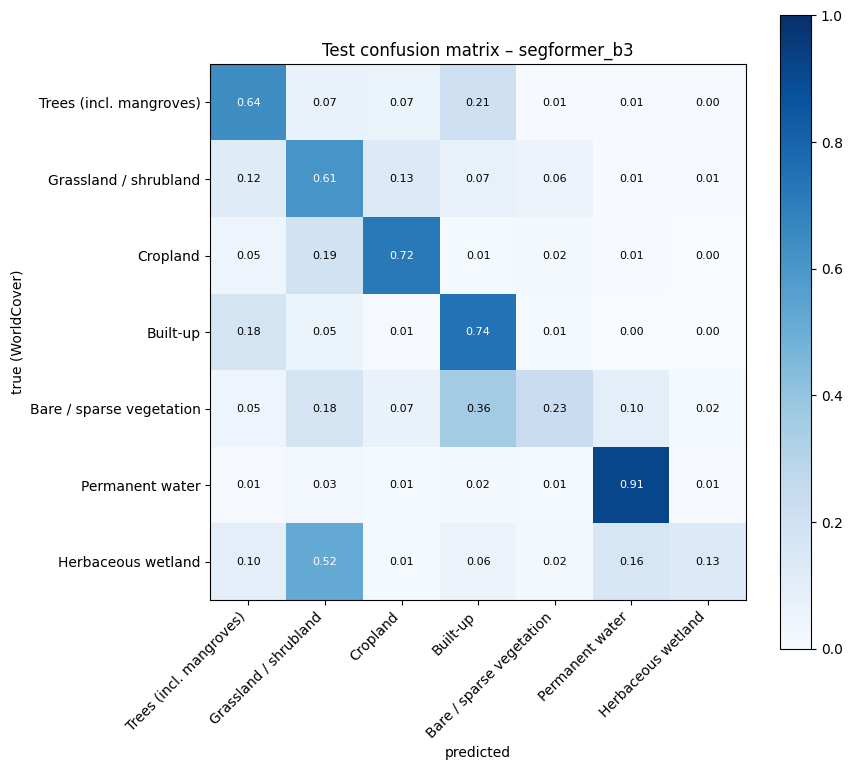

In [24]:
test_pred = results[best_name]["test_pred"]
test_cm = confusion(data["test"]["y"], test_pred)
test_result = results[best_name]["test"]

print(f"Selected: {best_name}")
print(f"Test OA:   {test_result['oa']:.3f}")
print(f"Test mIoU: {test_result['miou']:.3f}\n")
print(f"{'class':<26}{'IoU':>8}{'F1':>8}{'pixels':>12}")
for i, name in enumerate(CLASSES):
    print(f"{name:<26}{test_result['iou'][i]:8.3f}{test_result['f1'][i]:8.3f}{test_cm[i].sum():12,}")

row_sums = test_cm.sum(axis=1, keepdims=True)
cm_normalised = np.divide(test_cm, row_sums, out=np.zeros(test_cm.shape), where=row_sums > 0)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_normalised, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(N_CLASSES), CLASSES)
ax.set_xlabel("predicted")
ax.set_ylabel("true (WorldCover)")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{cm_normalised[i, j]:.2f}", ha="center", va="center",
                color="white" if cm_normalised[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im)
ax.set_title(f"Test confusion matrix – {best_name}")
plt.tight_layout()
plt.show()

In [25]:
test_meta = data["test"]["meta"]
test_areas = sorted({row[0] for row in test_meta})
test_months = sorted({int(row[2]) for row in test_meta})

print(f"{'area':<16}{'continent':<16}" + "".join(f"{name[:12]:>14}" for name in results))
for area in test_areas:
    idx = [i for i, row in enumerate(test_meta) if row[0] == area]
    line = f"{area:<16}{test_meta[idx[0]][1]:<16}"
    for name in results:
        line += f"{scores(confusion(data['test']['y'][idx], results[name]['test_pred'][idx]))['miou']:14.3f}"
    print(line)

print(f"\n{'month':<8}" + "".join(f"{name[:12]:>14}" for name in results))
for month in test_months:
    idx = [i for i, row in enumerate(test_meta) if int(row[2]) == month]
    line = f"{month:<8}"
    for name in results:
        line += f"{scores(confusion(data['test']['y'][idx], results[name]['test_pred'][idx]))['miou']:14.3f}"
    print(line)

area            continent         segformer_b2  segformer_b3  unet_resnet5  deeplabv3plu  unet_scratch  unet_resnet5
Christchurch    Oceania                  0.352         0.359         0.295         0.335         0.311         0.337
Cordoba_edge    South America            0.387         0.391         0.301         0.318         0.210         0.271
Hanoi_edge      Asia                     0.335         0.354         0.335         0.302         0.267         0.308
Portland_edge   North America            0.353         0.356         0.350         0.349         0.254         0.317
Pretoria_edge   Africa                   0.266         0.284         0.258         0.284         0.269         0.251
Toulouse        Europe                   0.383         0.387         0.371         0.378         0.331         0.335

month     segformer_b2  segformer_b3  unet_resnet5  deeplabv3plu  unet_scratch  unet_resnet5
1                0.426         0.431         0.399         0.410         0.322         

## Best and worst test patches (selected model)

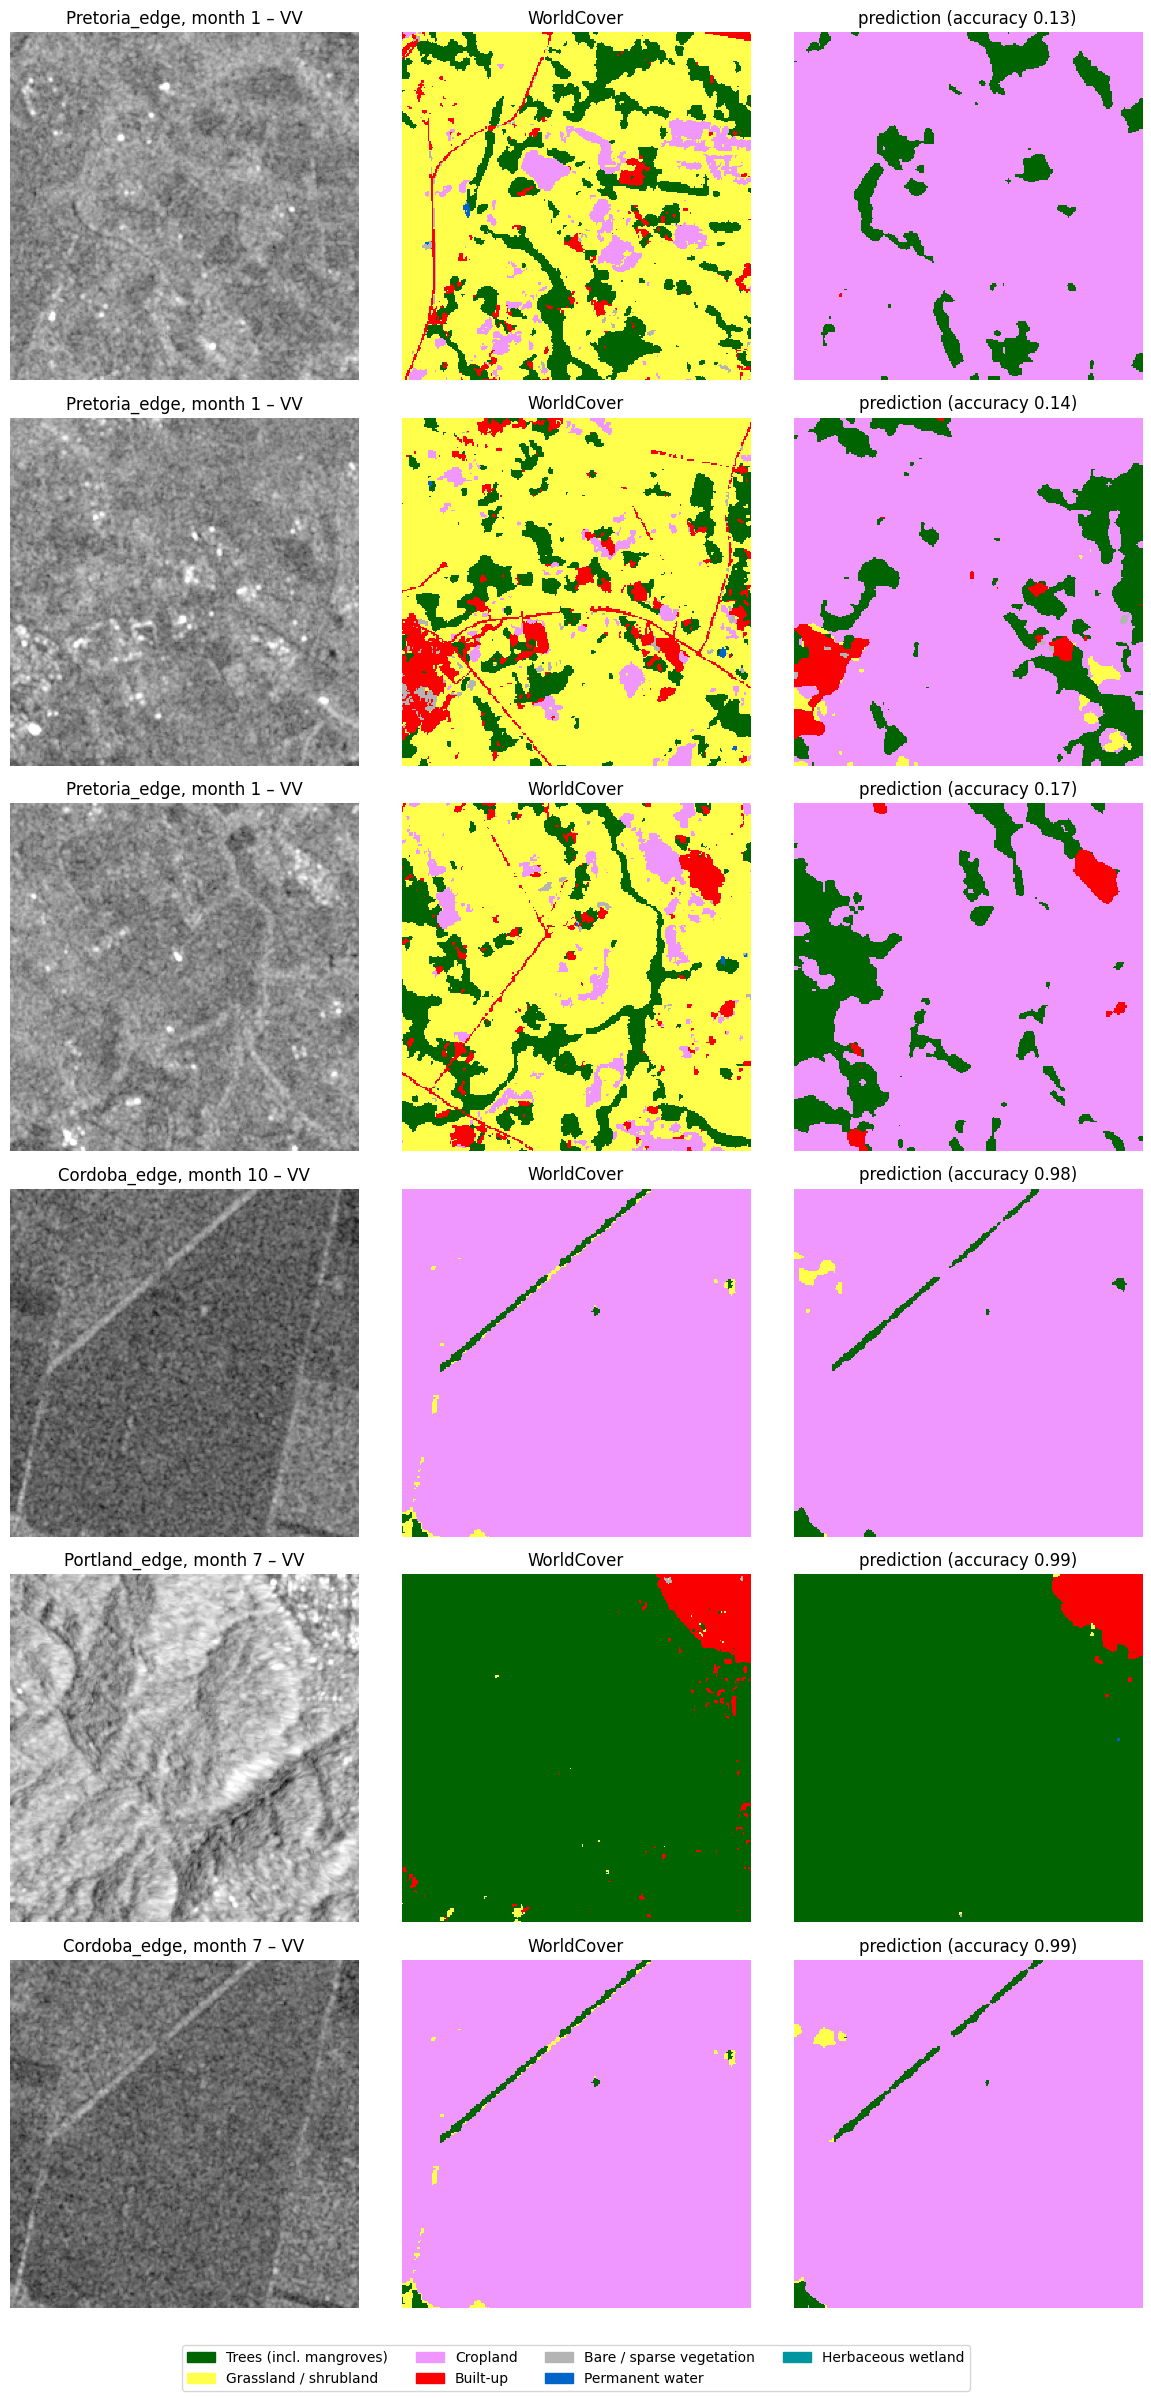

In [26]:
cmap = ListedColormap(COLORS)


def patch_accuracy(i):
    valid = data["test"]["y"][i] != IGNORE
    return (data["test"]["y"][i][valid] == test_pred[i][valid]).mean()


accuracies = np.array([patch_accuracy(i) for i in range(len(test_pred))])
order = np.argsort(accuracies)
chosen = list(order[:3]) + list(order[-3:])

fig, axes = plt.subplots(len(chosen), 3, figsize=(12, 4 * len(chosen)))
for row, i in enumerate(chosen):
    area, continent, month, r, c = test_meta[i]
    axes[row, 0].imshow(data["test"]["x"][i][..., 0].astype(np.float32), cmap="gray", vmin=-25, vmax=0)
    axes[row, 0].set_title(f"{area}, month {month} – VV")
    axes[row, 1].imshow(np.ma.masked_equal(data["test"]["y"][i], IGNORE), cmap=cmap,
                        vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation="nearest")
    axes[row, 1].set_title("WorldCover")
    axes[row, 2].imshow(test_pred[i], cmap=cmap, vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation="nearest")
    axes[row, 2].set_title(f"prediction (accuracy {accuracies[i]:.2f})")
    for ax in axes[row]:
        ax.axis("off")
fig.legend(handles=[Patch(color=c, label=n) for c, n in zip(COLORS, CLASSES)], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

# Save the selected model for the prototype

In [27]:
import shutil

best_model = load_trained(best_name)
best_model.save(model_folder / "lulc_model.keras")
# the normalisation that belongs to the selected model (candidates use the statistics of all 55 areas)
shutil.copy(model_folder / best_name / "normalisation.json", model_folder / "normalisation.json")
(model_folder / "model_info.json").write_text(json.dumps({
    "model": best_name,
    "round": 3,
    "classes": CLASSES,
    "colors": COLORS,
    "ignore": IGNORE,
    "patch_size": 256,
    "needs_keras_hub": best_name.startswith("segformer"),
    "validation_miou": float(results[best_name]["valid"]["miou"]),
    "test_miou": float(results[best_name]["test"]["miou"]),
    "test_oa": float(results[best_name]["test"]["oa"]),
}, indent=2))

# reload check: same predictions before and after saving
check_x = next(iter(valid_ds))[0]
before = np.asarray(best_model.predict_on_batch(check_x))
after = np.asarray(keras.models.load_model(model_folder / "lulc_model.keras", compile=False).predict_on_batch(check_x))
assert after.shape == (check_x.shape[0], 256, 256, N_CLASSES)
np.testing.assert_allclose(after.sum(axis=-1), 1.0, atol=1e-3)
np.testing.assert_allclose(after, before, atol=1e-2)
print(f"same class after reload for {100 * np.mean(before.argmax(-1) == after.argmax(-1)):.2f}% of the pixels")
print("saved in models/round3/: lulc_model.keras, normalisation.json, model_info.json, environment.json")

same class after reload for 100.00% of the pixels
saved in models/round3/: lulc_model.keras, normalisation.json, model_info.json, environment.json
